# Project: Supervised Learning

# Customer Churn

The monthly number of customers leaving the bank has increased. Keeping existing customers is cheaper than attracting new ones.

**Goals and tasks:**
- Analyze historical data on the behavior of bank customers and contract terminations. Predict whether a customer leaves the bank.
- Build a classification model with the quality metric f1 (minimum value 0.59).
- Measure AUC-ROC and compare it with the f1 score.

**Plan:**
- 1. Data preparation
    - 1.1 Data loading
    - 1.2 Feature preparation
    - 1.3 Transformation of the `Tenure` feature
- 2. Problem exploration
    - 2.1 Decision tree
    - 2.2 Random forest
    - 2.3 Logistic regression
- 3. Class imbalance
    - 3.1 Class weighting
    - 3.2 Upsampling and downsampling
- 4. Model testing
- 5. Overall conclusion

**Data description:**
Historical data on the behavior of customers and contract terminations with the bank.
Data source: https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling

**Features**
- `RowNumber` - row index in the data
- `CustomerId` - unique customer identifier
- `Surname` - surname
- `CreditScore` - credit score
- `Geography` - country of residence
- `Gender` - gender
- `Age` - age
- `Tenure` - number of properties owned by the customer
- `Balance` - account balance
- `NumOfProducts` - number of bank products used by the customer
- `HasCrCard` - whether the customer has a credit card
- `IsActiveMember` - customer activity
- `EstimatedSalary` - estimated salary

**Target**
- `Exited` - whether the customer left

# 1. Data Preparation

## 1.1 Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, r2_score
from sklearn.utils import shuffle

Load the data from the file `Churn.csv` and print the first 10 rows. Use `info()` to check the table structure: data types, number of rows and columns, missing values.

In [2]:
# read the data from the .csv file with read_csv()
users = pd.read_csv('Churn.csv')
# print the first 10 rows of the table with head()
display(users.head(10))
# study the table structure with info(): data types, number of rows and columns, missing values
users.info()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8.0,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7.0,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4.0,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4.0,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2.0,134603.88,1,1,1,71725.73,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


## 1.2 Feature Preparation

**1)** The features `RowNumber`, `CustomerId` and `Surname` do not carry information needed for classification. Drop them.

In [3]:
users = users.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

**2)** Look at the distributions of the numerical features.

In [4]:
def show_hists(data, data_label, num_bins, rug=False, log_scale=False):
    """
    input: data - data for the histogram
           data_label - data description
           num_bins - number of bins
    output: None
    description: builds a histogram and a boxplot for the chosen parameter:
                - distribution density (seaborn distplot())
                - boxplot (seaborn boxplot())
    """
    sns.set()
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label + ". Distribution density", fontsize=18)
    axes[0].set_ylabel('density', fontsize=15)
    sns.distplot(data, bins=num_bins, rug=rug, ax=axes[0])
    axes[1].set_title(data_label + ". Boxplot", fontsize=18)
    sns.boxplot(data=users, x=data_label, ax=axes[1])
    plt.show()

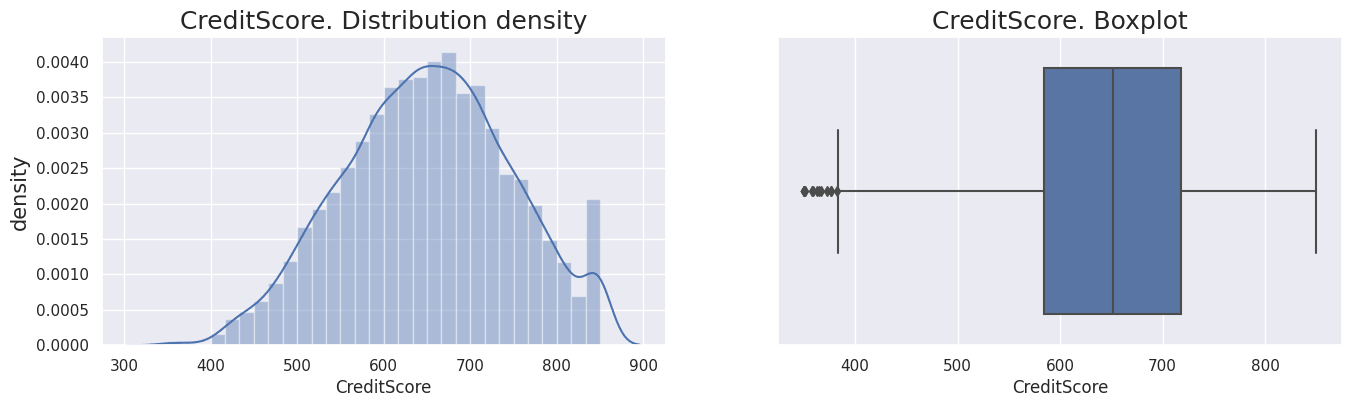

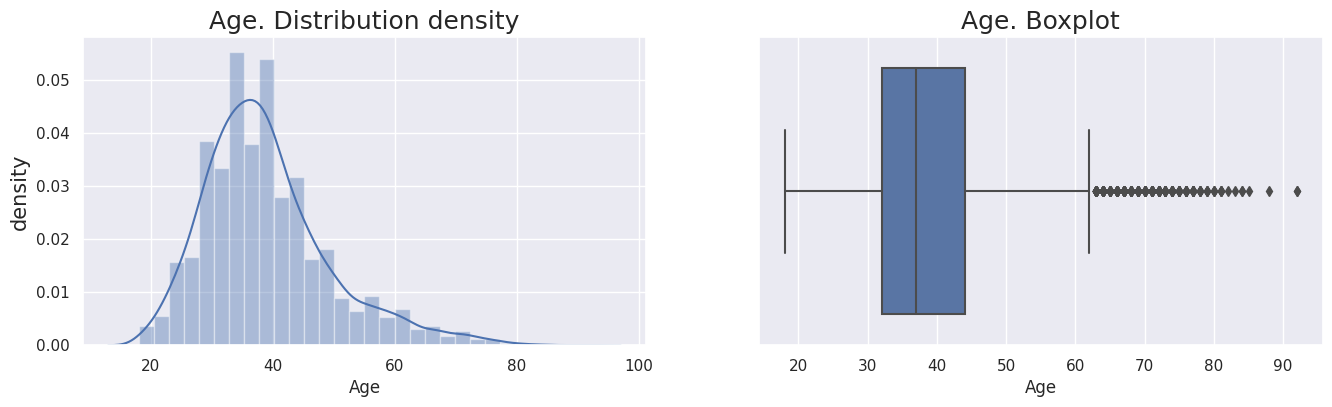

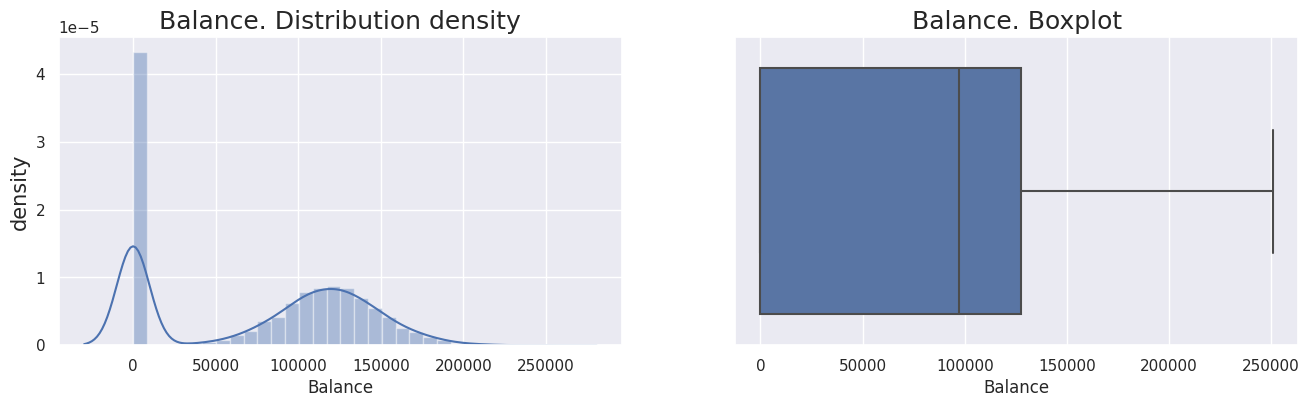

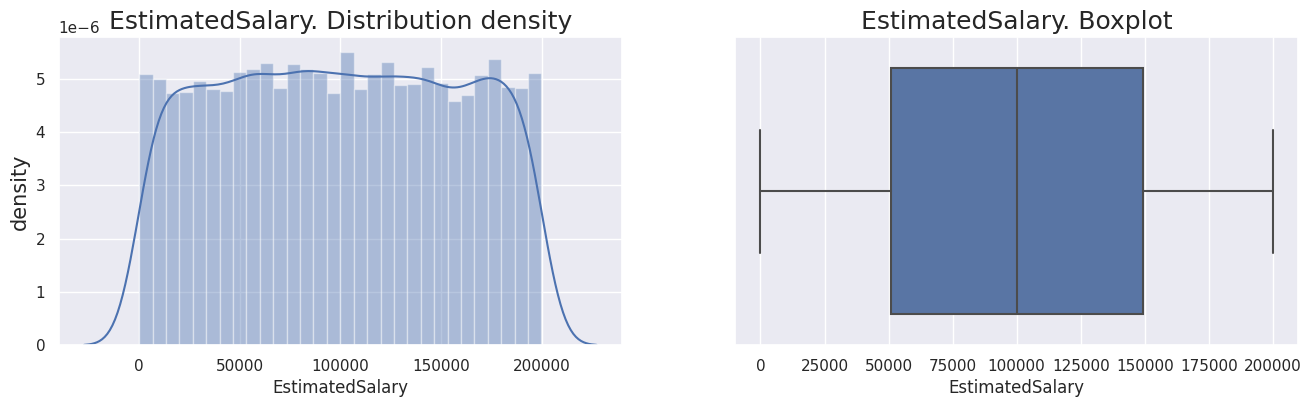

In [5]:
numerics = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
for column in numerics:
    show_hists(users[column], column, num_bins=30)

- The features `CreditScore` and `Age` have outliers. Find their share in the data.

In [6]:
# calculate the quantiles with quantile()
# the outlier border is calculated by the formula  [ q.75 + (q.75 - q.25)*1.5 ]
max_age = (users['Age'].quantile(0.75) - users['Age'].quantile(0.25))*1.5 + users['Age'].quantile(0.75)
rate = round(len(users.loc[users['Age'] > max_age]) / len(users) * 100, 2)
print('Share of outliers in the parameter {}: {} %'.format('Age', rate))

Share of outliers in the parameter Age: 3.59 %


In [7]:
# the outlier border is calculated by the formula  [ q.25 - (q.75 - q.25)*1.5 ]
min_score = users['CreditScore'].quantile(0.25) - \
            (users['CreditScore'].quantile(0.75) - users['CreditScore'].quantile(0.25))*1.5
rate = round(len(users.loc[users['CreditScore'] < min_score]) / len(users) * 100, 2)
print('Share of outliers in the parameter {}: {} %'.format('CreditScore', rate))

Share of outliers in the parameter CreditScore: 0.15 %


The total share of outliers is small (less than 4%). They are not removed for now.

- Scale the numerical features `CreditScore`, `Age`, `Balance`, `EstimatedSalary` with `StandardScaler` from `sklearn`.

In [8]:
scaler = StandardScaler()
users[numerics] = scaler.fit_transform(users[numerics])

**3)** Look at the distributions of the categorical features.

In [9]:
def show_hists(data, data_label1, data_label2=''):
    """
    input: data - data for the histogram
           data_label1,2 - feature names
    output: None
    description: builds a countplot for two features
    """
    sns.set()
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label1 + ". CountPlot", fontsize=18)
    sns.countplot(data=users, x=data_label1, ax=axes[0])
    if data_label2 != '':
        axes[1].set_title(data_label2 + ". CountPlot", fontsize=18)
        sns.countplot(data=users, x=data_label2, ax=axes[1])
    plt.show()

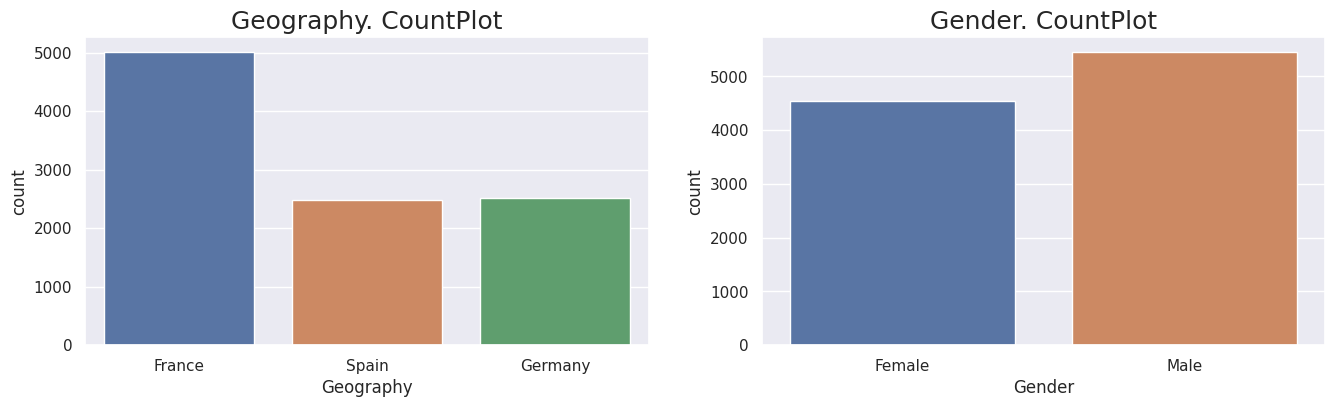

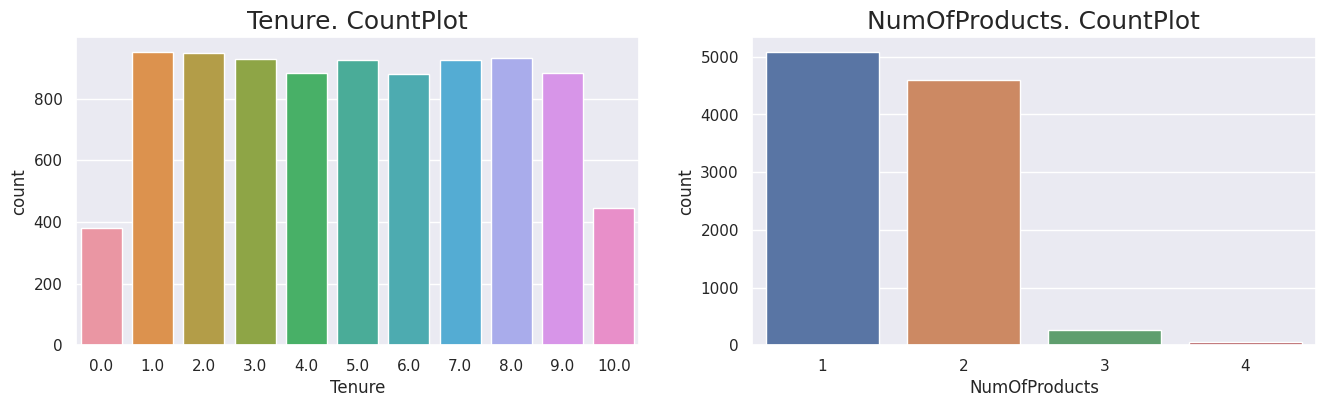

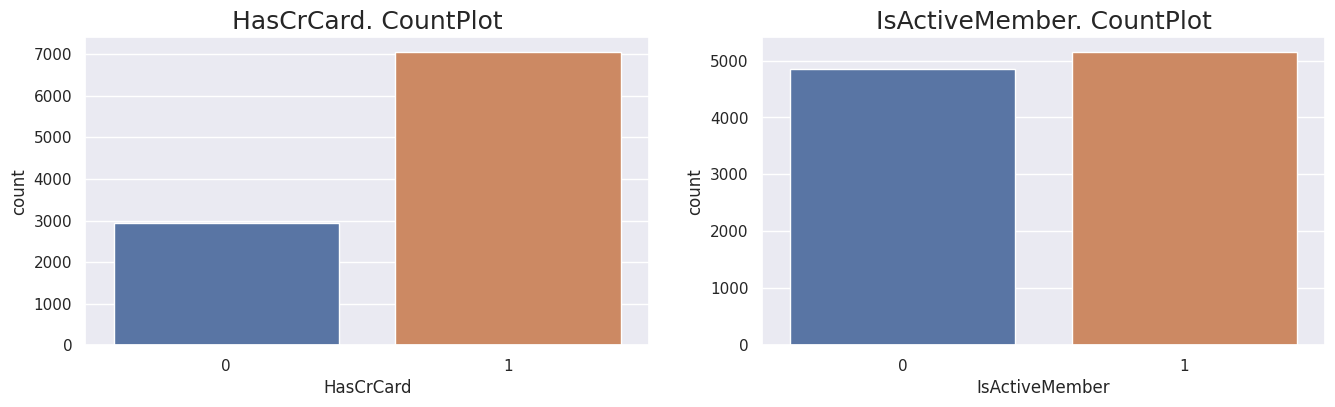

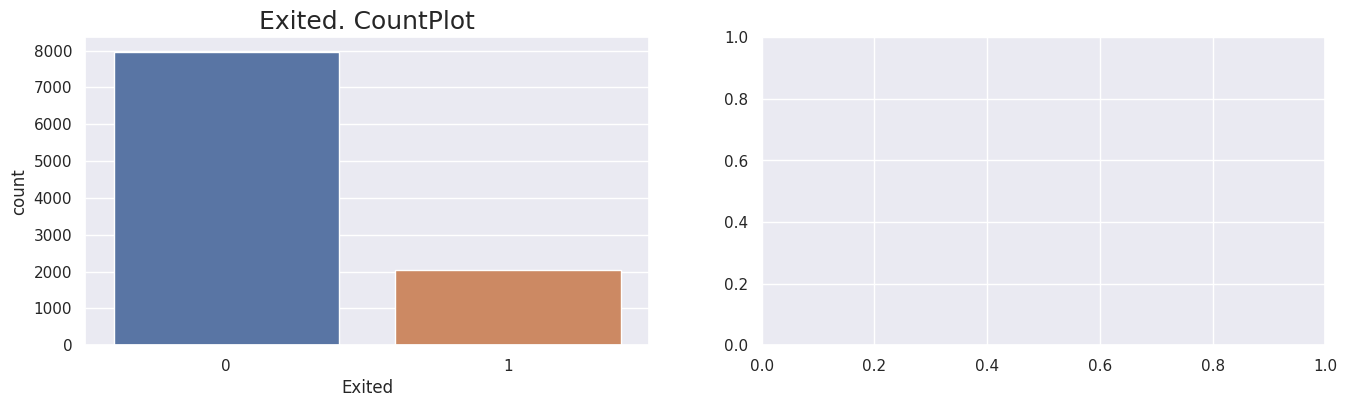

In [10]:
categoricals = ['Geography', 'Gender', 'Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited', '']
for i in range(len(categoricals)//2):
    show_hists(users, categoricals[2*i], categoricals[2*i+1])

- The target `Exited` is distributed about 4:1.
- The features `Geography` and `Gender` have few categories. Transform them with One-Hot Encoding.

In [11]:
# use pd.get_dummies for the transformation
# drop_first=True removes the redundant data column
users = pd.get_dummies(users, drop_first=True)

**4)** Convert the data types of `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `Exited` to `int8` to save memory.

In [12]:
for column in ['NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']:
    users[column] = users[column].astype('int8')

## 1.3 Transformation of the `Tenure` Feature

- The column `Tenure` has missing values (about 10%). The data may have been missing initially or lost because of failures when the database was exported.
- Try to build a model that predicts this parameter from the available data.

In [13]:
# save the data with missing 'Tenure' values in a separate variable
no_tenure_df = users.loc[users['Tenure'].isna()]
features = users.loc[~users['Tenure'].isna()]

In [14]:
# the main target 'Exited' is not used in this model
features = features.drop('Exited', axis=1)

In [15]:
# in this model 'Tenure' is the target
y = features['Tenure']
X = features.drop('Tenure', axis=1)
X = features[['EstimatedSalary', 'Age', 'CreditScore']]

In [16]:
# split the data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=123)

- Try classification with the "Random Forest" model. The feature `Tenure` is distributed uniformly between 11 values, so the model quality is estimated with accuracy.

In [17]:
# best_params and best_accuracy store the best model parameters and the highest accuracy
best_params = []
best_accuracy = 0
# loop over all chosen hyperparameters
for n_estimators in (1,10):
    for max_depth in range(2,10):
        for min_samples_split in range(2,10):
            for min_samples_leaf in range(1,8):
                for criterion in ['gini', 'entropy']:
                    # initialize the model with the current hyperparameters
                    model_rf_clf = RandomForestClassifier(random_state=123,
                                                          n_estimators=n_estimators,
                                                          max_depth=max_depth,
                                                          min_samples_split=min_samples_split,
                                                          min_samples_leaf=min_samples_leaf,
                                                          criterion=criterion)
                    # train the model on the training set
                    model_rf_clf.fit(X_train, y_train)
                    # predict on the validation set
                    predictions = model_rf_clf.predict(X_valid)
                    # calculate the model accuracy with accuracy_score
                    accuracy = accuracy_score(y_valid, predictions)
                    # if the current accuracy is higher than the previous best value, 
                    # save the model parameters and the current accuracy
                    if accuracy > best_accuracy:
                        best_params = [n_estimators, max_depth, min_samples_split, min_samples_leaf, criterion]
                        best_accuracy = accuracy

In [18]:
# print the best accuracy and the model parameters
print('''Best accuracy: {}
Model parameters:
   n_estimators = {}
   max_depth = {}
   min_samples_split = {}
   min_samples_leaf = {}
   criterion = {} '''.format(round(best_accuracy, 2),
                             best_params[0],
                             best_params[1],
                             best_params[2],
                             best_params[3],
                             best_params[4]
                            ))

Best accuracy: 0.12
Model parameters:
   n_estimators = 10
   max_depth = 5
   min_samples_split = 2
   min_samples_leaf = 2
   criterion = entropy 


- The model accuracy of 12% is too low (a random choice between 11 classes gives about 9%). Other classification models did not improve the quality.
- Regression models (treating `Tenure` as a quantitative feature) gave no positive result (r2 is close to 0 for LinearRegression and RandomForestRegressor).
- In this case `Tenure` is treated as a categorical feature and transformed with One-Hot Encoding, with the missing values as a separate category.

In [19]:
users.loc[users['Tenure'].isna(), 'Tenure'] = -1
users['Tenure'] = users['Tenure'].astype('object')
users = pd.get_dummies(users, drop_first=True)

- Print the info of the resulting table.

In [20]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  float64
 1   Age                10000 non-null  float64
 2   Balance            10000 non-null  float64
 3   NumOfProducts      10000 non-null  int8   
 4   HasCrCard          10000 non-null  int8   
 5   IsActiveMember     10000 non-null  int8   
 6   EstimatedSalary    10000 non-null  float64
 7   Exited             10000 non-null  int8   
 8   Geography_Germany  10000 non-null  uint8  
 9   Geography_Spain    10000 non-null  uint8  
 10  Gender_Male        10000 non-null  uint8  
 11  Tenure_0.0         10000 non-null  uint8  
 12  Tenure_1.0         10000 non-null  uint8  
 13  Tenure_2.0         10000 non-null  uint8  
 14  Tenure_3.0         10000 non-null  uint8  
 15  Tenure_4.0         10000 non-null  uint8  
 16  Tenure_5.0         1000

In [21]:
display(users.head(10))

,CreditScore,Age,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,...,Tenure_1.0,Tenure_2.0,Tenure_3.0,Tenure_4.0,Tenure_5.0,Tenure_6.0,Tenure_7.0,Tenure_8.0,Tenure_9.0,Tenure_10.0
0,-0.326221,0.293517,-1.225848,1,1,1,0.021886,1,0,0,...,0,1,0,0,0,0,0,0,0,0
1,-0.440036,0.198164,0.117350,1,0,1,0.216534,0,0,1,...,1,0,0,0,0,0,0,0,0,0
2,-1.536794,0.293517,1.333053,3,1,0,0.240687,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,0.501521,0.007457,-1.225848,2,0,0,-0.108918,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,2.063884,0.388871,0.785728,1,1,1,-0.365276,0,0,1,...,0,1,0,0,0,0,0,0,0,0
5,-0.057205,0.484225,0.597329,2,1,0,0.863650,1,0,1,...,0,0,0,0,0,0,0,1,0,0
6,1.774174,1.056346,-1.225848,2,1,1,-1.565487,0,0,0,...,0,0,0,0,0,0,1,0,0,0
7,-2.840488,-0.946079,0.618019,4,1,0,0.334854,1,1,0,...,0,0,0,1,0,0,0,0,0,0
8,-1.547141,0.484225,1.050820,2,0,1,-0.437329,0,0,0,...,0,0,0,1,0,0,0,0,0,0
9,0.346319,-1.136786,0.931463,1,1,1,-0.493230,0,0,0,...,0,1,0,0,0,0,0,0,0,0


### Conclusions

- The data is loaded and matches the description. There are no duplicates. The data types are converted according to the stored information.
- The features `RowNumber`, `CustomerId` and `Surname` are dropped because the target does not depend on them.
- The feature distributions are analyzed. About 4% of outliers are found in `CreditScore` and `Age`. They are left as is for now.
- The numerical features are standardized (mean = 0, standard deviation = 1).
- The categorical features are transformed with One-Hot Encoding.
- The target is distributed in the ratio **4:1**.
- About 10% of the values in `Tenure` are missing. An attempt to build a classification model to fill them gave no significant result (model accuracy 12%, against 9% for random filling). The feature is transformed with One-Hot Encoding.

# 2. Problem Exploration

- Split the data into features and the target.

In [22]:
features = users.drop('Exited', axis=1)
target = users['Exited']

- Split the data into training, validation and test sets in the ratio 3:1:1 (60% for training and 20% each for validation and test).

In [23]:
# split the data with train_test_split from sklearn
X, X_test, y, y_test = train_test_split(features, target, test_size=0.2, random_state=123)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=123)

In [24]:
# print the sizes of the resulting sets
print('Dataset sizes:')
print('X_train: ', X_train.shape)
print('X_valid: ', X_valid.shape)
print('X_test:  ', X_test.shape)

Dataset sizes:
X_train:  (6000, 21)
X_valid:  (2000, 21)
X_test:   (2000, 21)


- Train different classification models without accounting for the class imbalance.

## 2.1 Decision Tree

- Initialize the decision tree model DecisionTreeClassifier.
- Hyperparameters to tune:
    - `max_depth` - maximum depth of the tree
    - `min_samples_split` - minimum number of objects in a node
    - `min_samples_leaf` - minimum number of objects in a leaf
    - `criterion` ("gini" or "entropy") - function that measures the quality of a split
- The model quality is checked with `f1` and `roc_auc`.

In [25]:
def decision_tree(X_train, X_valid, y_train, y_valid, cw=None):
    """
    input: X_train, X_valid, y_train, y_valid - training and validation sets of features and target
            cw - class_weight parameter of the decision tree model
    output: None
    description: trains a DecisionTreeClassifier model with different combinations of hyperparameters;
                 model quality metrics: f1 and roc_auc;
                 prints the best metric values and the hyperparameters of the best model.
    """
    # best_params_f1 and best_f1 store the best model parameters and the highest f1 metric
    best_params_f1 = []
    best_f1 = 0
    # the same for the roc_auc metric.
    best_params_roc_auc = []
    best_roc_auc = 0.5
    # loop over all chosen hyperparameters
    for max_depth in range(2,10):
        for min_samples_split in range(2,6):
            for min_samples_leaf in range(1,10):
                for criterion in ['gini', 'entropy']:
                    # initialize the model with the current hyperparameters
                    model_dt_clf = DecisionTreeClassifier(random_state=123,
                                                          max_depth=max_depth,
                                                          min_samples_split=min_samples_split,
                                                          min_samples_leaf=min_samples_leaf,
                                                          criterion=criterion,
                                                          class_weight=cw)
                    # train the model on the training set
                    model_dt_clf.fit(X_train, y_train)
                    # predict on the validation set
                    predictions = model_dt_clf.predict(X_valid)
                    # calculate the model f1 with f1_score
                    f1 = f1_score(y_valid, predictions)
                    # if the current f1 is higher than the previous best value, 
                    # save the model parameters and the current f1
                    if f1 > best_f1:
                        best_params_f1 = [max_depth, min_samples_split, min_samples_leaf, criterion]
                        best_f1 = f1
                    # the same for the roc_auc metric
                    roc_auc = roc_auc_score(y_valid, predictions)
                    if roc_auc > best_roc_auc:
                        best_params_roc_auc = [max_depth, min_samples_split, min_samples_leaf, criterion]
                        best_roc_auc = roc_auc
    
    # print the best f1 metric and the model parameters.
    print('''Best f1 metric: {}
    Model parameters:
       max_depth = {}
       min_samples_split = {}
       min_samples_leaf = {}
       criterion = {} \n'''.format(round(best_f1, 3),
                                 best_params_f1[0],
                                 best_params_f1[1],
                                 best_params_f1[2],
                                 best_params_f1[3]
                                ))
    
    # print the best roc_auc metric and the model parameters.
    print('''Best roc_auc metric: {}
    Model parameters:
       max_depth = {}
       min_samples_split = {}
       min_samples_leaf = {}
       criterion = {} '''.format(round(best_roc_auc, 3),
                                 best_params_roc_auc[0],
                                 best_params_roc_auc[1],
                                 best_params_roc_auc[2],
                                 best_params_roc_auc[3]
                                ))

In [26]:
decision_tree(X_train, X_valid, y_train, y_valid)

Best f1 metric: 0.569
    Model parameters:
       max_depth = 5
       min_samples_split = 2
       min_samples_leaf = 4
       criterion = gini 

Best roc_auc metric: 0.711
    Model parameters:
       max_depth = 5
       min_samples_split = 2
       min_samples_leaf = 4
       criterion = gini 


- The best f1 for the decision tree is 0.57 (not enough according to the task).
- The best results for f1 and roc_auc are reached with the same hyperparameters.
- Try other models to improve the result.

## 2.2 Random Forest

- Initialize the random forest model RandomForestClassifier.
- Hyperparameters to tune:
    - `n_estimators` - number of trees
    - `max_depth` - maximum depth of the tree
    - `min_samples_split` - minimum number of objects in a node
    - `min_samples_leaf` - minimum number of objects in a leaf
- The model quality is checked with `f1` and `roc_auc`.

In [27]:
def random_forest(X_train, X_valid, y_train, y_valid, cw=None):
    """
    input: X_train, X_valid, y_train, y_valid - training and validation sets of features and target
            cw - class_weight parameter of the random forest model
    output: None
    description: trains a RandomForestClassifier model with different combinations of hyperparameters;
                 model quality metrics: f1 and roc_auc;
                 prints the best metric values and the hyperparameters of the best model.
    """
    # best_params_f1 and best_f1 store the best model parameters and the highest f1 metric
    best_params_f1 = []
    best_f1 = 0
    # the same for the roc_auc metric.
    best_params_roc_auc = []
    best_roc_auc = 0.5
    # loop over all chosen hyperparameters
    for n_estimators in range(30,40):
        for max_depth in range(10,17,2):
            for min_samples_split in range(2,5):
                for min_samples_leaf in range(1,4):
                    # initialize the model with the current hyperparameters
                    model_rf_clf = RandomForestClassifier(random_state=123,
                                                          n_estimators=n_estimators,
                                                          max_depth=max_depth,
                                                          min_samples_split=min_samples_split,
                                                          min_samples_leaf=min_samples_leaf)
                    # train the model on the training set
                    model_rf_clf.fit(X_train, y_train)
                    # predict on the validation set
                    predictions = model_rf_clf.predict(X_valid)

                    # calculate the model f1 with f1_score
                    f1 = f1_score(y_valid, predictions)
                    # if the current f1 is higher than the previous best value, 
                    # save the model parameters and the current f1
                    if f1 > best_f1:
                        best_params_f1 = [n_estimators, max_depth, min_samples_split, min_samples_leaf]
                        best_f1 = f1
                    # the same for the roc_auc metric
                    roc_auc = roc_auc_score(y_valid, predictions)
                    if roc_auc > best_roc_auc:
                        best_params_roc_auc = [n_estimators, max_depth, min_samples_split, min_samples_leaf]
                        best_roc_auc = roc_auc

    # print the best f1 metric and the model parameters.
    print('''Best f1 metric: {}
    Model parameters:
       n_estimators = {}
       max_depth = {}
       min_samples_split = {}
       min_samples_leaf = {} \n'''.format(round(best_f1, 3),
                                 best_params_f1[0],
                                 best_params_f1[1],
                                 best_params_f1[2],
                                 best_params_f1[3]
                                ))

    # print the best roc_auc metric and the model parameters.
    print('''Best roc_auc metric: {}
    Model parameters:
       n_estimators = {}
       max_depth = {}
       min_samples_split = {}
       min_samples_leaf = {} '''.format(round(best_roc_auc, 3),
                                 best_params_roc_auc[0],
                                 best_params_roc_auc[1],
                                 best_params_roc_auc[2],
                                 best_params_roc_auc[3]
                                ))

In [28]:
random_forest(X_train, X_valid, y_train, y_valid)

Best f1 metric: 0.575
    Model parameters:
       n_estimators = 30
       max_depth = 16
       min_samples_split = 2
       min_samples_leaf = 3 

Best roc_auc metric: 0.707
    Model parameters:
       n_estimators = 30
       max_depth = 16
       min_samples_split = 2
       min_samples_leaf = 3 


- The best f1 for the random forest is 0.58 (not enough according to the task).
- The best results for f1 and roc_auc are reached with the same hyperparameters.
- Try other models to improve the result.

## 2.3 Logistic Regression

- Initialize the logistic regression model LogisticRegression.
- Hyperparameter to tune:
    - `C` - inverse of the regularization strength
- The model quality is checked with `f1` and `roc_auc`.

In [29]:
# best_params_f1 and best_f1 store the best model parameters and the highest f1 metric
best_params_f1 = []
best_f1 = 0
# the same for the roc_auc metric.
best_params_roc_auc = []
best_roc_auc = 0.5

#cs = np.linspace(0.01, 100, 1000, endpoint=True)
cs = range(1, 100)
# loop over all chosen hyperparameters
for C in cs:
    # initialize the model with the current hyperparameters
    model_lr_clf = LogisticRegression(random_state=123,
                                      C=C,
                                      max_iter=1000)
    # train the model on the training set
    model_lr_clf.fit(X_train, y_train)
    # predict on the validation set
    predictions = model_lr_clf.predict(X_valid)

    # calculate the model f1 with f1_score
    f1 = f1_score(y_valid, predictions)
    # if the current f1 is higher than the previous best value, 
    # save the model parameters and the current f1
    if f1 > best_f1:
        best_params_f1 = [C]
        best_f1 = f1
    # the same for the roc_auc metric
    roc_auc = roc_auc_score(y_valid, predictions)
    if roc_auc > best_roc_auc:
        best_params_roc_auc = [C]
        best_roc_auc = roc_auc

In [30]:
# print the best f1 metric and the model parameters.
print('''Best f1 metric: {}
Model parameters:
   C = {} '''.format(round(best_f1, 3),
                             best_params_f1[0]
                            ))

Best f1 metric: 0.279
Model parameters:
   C = 5 


In [31]:
# print the best roc_auc metric and the model parameters.
print('''Best roc_auc metric: {}
Model parameters:
   C = {} '''.format(round(best_roc_auc, 3),
                             best_params_roc_auc[0]
                            ))

Best roc_auc metric: 0.574
Model parameters:
   C = 5 


- The best f1 for the logistic regression is 0.27 (worse than for the other models).
- The best results for f1 and roc_auc are reached with the same hyperparameters.
- Try to improve the result by dealing with the class imbalance.

### Conclusions

- The data is split into training, validation and test sets in the ratio 3:1:1.
- The models "Decision Tree", "Random Forest" and "Logistic Regression" are trained without accounting for the class imbalance. The maximum **f1 = 0.58** is reached with the random forest. The model quality does not meet the requirement of the task.
- The model quality is also estimated with roc_auc. The maximum **roc_auc = 0.71** is reached with the random forest.
- The metrics f1 and roc_auc reach their maximum values with the same hyperparameters (this is not always the case).

# 3. Class Imbalance

- The ratio of the target values is 4:1 (for classes 0 and 1 respectively).
- To deal with the class imbalance, try:
    - class weighting (class_weight='balanced')
    - increasing the sample of the positive class (copying objects)
    - decreasing the sample of the negative class (sampling)
    - shuffling the objects with shuffle

## 3.1 Class Weighting

In [32]:
decision_tree(X_train, X_valid, y_train, y_valid, cw='balanced')

Best f1 metric: 0.565
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 9
       criterion = gini 

Best roc_auc metric: 0.751
    Model parameters:
       max_depth = 6
       min_samples_split = 2
       min_samples_leaf = 8
       criterion = gini 


- Class weighting gave almost no gain in f1 for the decision tree.
- In this case the best values of f1 and roc_auc are reached with different hyperparameters.
- Apply upsampling and downsampling and check the results on the random forest model (it gave the best result in the initial exploration).

## 3.2 Upsampling and Downsampling

- Write functions that increase and decrease the samples.

In [33]:
def upsample(features, target, repeat):
    """
    input:        features - features 
                  target - target
                  repeat (int) - multiplier for repeating the features
    output:       features_upsampled - upsampled features
                  target_upsampled - upsampled target
    description:  splits the features by the target classes (0, 1),
                  repeats the features of the positive class repeat times,
                  concatenates the objects with different targets with concat,
                  shuffles the objects with shuffle
    """
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]
    
    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)
    
    features_upsampled, target_upsampled = shuffle(
        features_upsampled, target_upsampled, random_state=12345)
    return features_upsampled, target_upsampled

In [34]:
def downsample(features, target, fraction):
    """
    input:        features - features 
                  target - target
                  fraction (float) - share of objects to sample
    output:       features_downsampled - downsampled features
                  target_downsampled - downsampled target
    description:  splits the features by the target classes (0, 1), 
                  samples the features of the negative class 0 (with the coefficient fraction),
                  concatenates the objects with different targets with concat,
                  shuffles the objects with shuffle
    """
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]
    
    features_downsampled = pd.concat(
        [features_zeros.sample(frac=fraction, random_state=12345)] + [features_ones])
    target_downsampled = pd.concat(
        [target_zeros.sample(frac=fraction, random_state=12345)] + [target_ones])
    
    features_downsampled, target_downsampled = shuffle(
        features_downsampled, target_downsampled, random_state=12345)
    return features_downsampled, target_downsampled

- For the training set, increase the number of class 1 objects 2 times and decrease the number of class 0 objects 1.5 times.

In [35]:
X_train_upsampled, y_train_upsampled = upsample(X_train, y_train, 2)
X_train_balanced, y_train_balanced = downsample(X_train_upsampled, y_train_upsampled, 0.75)

- Train the random forest and decision tree models on the balanced training sets.

In [36]:
random_forest(X_train_balanced, X_valid, y_train_balanced, y_valid)

Best f1 metric: 0.608
    Model parameters:
       n_estimators = 33
       max_depth = 12
       min_samples_split = 3
       min_samples_leaf = 1 

Best roc_auc metric: 0.748
    Model parameters:
       n_estimators = 33
       max_depth = 12
       min_samples_split = 3
       min_samples_leaf = 1 


In [37]:
decision_tree(X_train_balanced, X_valid, y_train_balanced, y_valid)

Best f1 metric: 0.587
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 2
       criterion = gini 

Best roc_auc metric: 0.75
    Model parameters:
       max_depth = 6
       min_samples_split = 2
       min_samples_leaf = 1
       criterion = gini 


- The f1 of the "Random Forest" model reached **0.61** on the balanced set, which meets the requirement of the task (>0.59).
- The f1 of the "Decision Tree" model also almost reached the minimum allowed value of 0.59 (with a shorter training time).
- The best values of f1 and roc_auc were reached on the random forest with the same hyperparameters. For the decision tree the optimal hyperparameters differ.
- The maximum roc_auc of the decision tree, **0.75**, is slightly higher than that of the random forest, **0.748**.

- For the random forest model, try different variants of upsampling and downsampling (change the parameters repeat and fraction).

In [38]:
for rep in range(2,4):
    for frac in np.arange(0.5, 0.8, 0.05):
        print('=============================================================')
        print('repeat = {};   fraction = {}'.format(rep, round(frac,2)))
        X_train_upsampled, y_train_upsampled = upsample(X_train, y_train, rep)
        X_train_balanced, y_train_balanced = downsample(X_train_upsampled, y_train_upsampled, frac)
        decision_tree(X_train_balanced, X_valid, y_train_balanced, y_valid)

repeat = 2;   fraction = 0.5


Best f1 metric: 0.576
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 3
       criterion = gini 

Best roc_auc metric: 0.757
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 6
       criterion = gini 
repeat = 2;   fraction = 0.55


Best f1 metric: 0.604
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 4
       criterion = gini 

Best roc_auc metric: 0.769
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 4
       criterion = gini 
repeat = 2;   fraction = 0.6


Best f1 metric: 0.582
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 7
       criterion = entropy 

Best roc_auc metric: 0.758
    Model parameters:
       max_depth = 7
       min_samples_split = 5
       min_samples_leaf = 2
       criterion = gini 
repeat = 2;   fraction = 0.65


Best f1 metric: 0.582
    Model parameters:
       max_depth = 8
       min_samples_split = 2
       min_samples_leaf = 3
       criterion = gini 

Best roc_auc metric: 0.755
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 8
       criterion = gini 
repeat = 2;   fraction = 0.7


...

Best f1 metric: 0.552
    Model parameters:
       max_depth = 5
       min_samples_split = 2
       min_samples_leaf = 8
       criterion = gini 

Best roc_auc metric: 0.748
    Model parameters:
       max_depth = 5
       min_samples_split = 2
       min_samples_leaf = 8
       criterion = gini 
repeat = 3;   fraction = 0.65


Best f1 metric: 0.555
    Model parameters:
       max_depth = 9
       min_samples_split = 2
       min_samples_leaf = 1
       criterion = entropy 

Best roc_auc metric: 0.747
    Model parameters:
       max_depth = 5
       min_samples_split = 2
       min_samples_leaf = 1
       criterion = entropy 
repeat = 3;   fraction = 0.7


Best f1 metric: 0.57
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 6
       criterion = gini 

Best roc_auc metric: 0.758
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 6
       criterion = gini 
repeat = 3;   fraction = 0.75


Best f1 metric: 0.575
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 2
       criterion = gini 

Best roc_auc metric: 0.753
    Model parameters:
       max_depth = 7
       min_samples_split = 2
       min_samples_leaf = 2
       criterion = gini 
repeat = 3;   fraction = 0.8


Best f1 metric: 0.574
    Model parameters:
       max_depth = 9
       min_samples_split = 2
       min_samples_leaf = 6
       criterion = gini 

Best roc_auc metric: 0.754
    Model parameters:
       max_depth = 6
       min_samples_split = 2
       min_samples_leaf = 5
       criterion = gini 


- The best result for the decision tree is reached when the positive class of the training set is increased 2 times and the negative class is sampled with the coefficient 0.55. In this case **f1 = 0.604** and **roc_auc = 0.769**, which meets the requirements of the task.

### Conclusions

- Class weighting with the class_weight parameter did not significantly increase f1.
- Upsampling of the positive class and downsampling of the negative class gave the required gain in model accuracy.
- The models that reached the required quality on the validation set:
    - Random forest:
        - f1 = 0.608
        - roc_auc = 0.748
        - repeat = 2         - repetition of class 1 objects
        - fraction = 0.75    - sampling coefficient of class 0 objects
    - Decision tree:
        - f1 = 0.604
        - roc_auc = 0.769
        - repeat = 2
        - fraction = 0.55

# 4. Model Testing

- Train the obtained models on all available data (training + validation), after balancing the classes with the repeat and fraction coefficients found earlier.
- Calculate f1 and roc_auc on the test set.

**1) "Random Forest" model**

In [39]:
X_upsampled, y_upsampled = upsample(X, y, 2)
X_balanced, y_balanced = downsample(X_upsampled, y_upsampled, 0.75)
model_rfc_final = RandomForestClassifier(random_state=123,
                                         n_estimators=33,
                                         max_depth=12,
                                         min_samples_split=3,
                                         min_samples_leaf=1)
model_rfc_final.fit(X_balanced, y_balanced)
predictions = model_rfc_final.predict(X_test)
f1 = f1_score(y_test, predictions)
roc_auc = roc_auc_score(y_test, predictions)
print(' f1 = {}, \n roc_auc = {}'.format(round(f1,2), round(roc_auc,2)))

 f1 = 0.63, 
 roc_auc = 0.77


**2) "Decision Tree" model**

In [40]:
X_upsampled, y_upsampled = upsample(X, y, 2)
X_balanced, y_balanced = downsample(X_upsampled, y_upsampled, 0.55)
model_dtc_final = DecisionTreeClassifier(random_state=123,
                                         max_depth=8,
                                         min_samples_split=2,
                                         min_samples_leaf=4)
model_dtc_final.fit(X_balanced, y_balanced)
predictions = model_dtc_final.predict(X_test)
f1 = f1_score(y_test, predictions)
roc_auc = roc_auc_score(y_test, predictions)
print(' f1 = {}, \n roc_auc = {}'.format(round(f1,2), round(roc_auc,2)))

 f1 = 0.62, 
 roc_auc = 0.78


### Conclusions

- A value of f1 that meets the requirement of the task (on the test set) is reached with two models:
    - Random forest
        f1 = 0.63
        roc_auc = 0.77
    - Decision tree
        f1 = 0.62
        roc_auc = 0.78
- The random forest has the higher f1, and the decision tree has the higher roc_auc.

# 5. Overall Conclusion

- The data is preprocessed.
    - The numerical features are standardized (mean = 0, standard deviation = 1). The categorical features are transformed with One-Hot Encoding.
    - The target is distributed in the ratio **4:1**.
    - About 10% of the values in `Tenure` are missing. An attempt to build a classification model to fill them gave no significant result (model accuracy 12%, against 9% for random filling). The feature is transformed with One-Hot Encoding.
- The models are analyzed without accounting for the class imbalance.
    - The data is split into training, validation and test sets in the ratio 3:1:1.
    - The models "Decision Tree", "Random Forest" and "Logistic Regression" are trained without accounting for the class imbalance. The maximum **f1 = 0.58** is reached with the random forest.
    - The model quality is also estimated with roc_auc. The maximum **roc_auc = 0.71** is reached with the random forest.
    - The metrics f1 and roc_auc reach their maximum values with the same hyperparameters.
- The class imbalance is analyzed.
    - Class weighting with the class_weight parameter did not significantly increase f1.
    - Upsampling of the positive class and downsampling of the negative class gave the required gain in model accuracy.
    - The models that reached the required **f1 on the validation set**:
        - **Random forest**:
            - **f1 = 0.608**
            - **roc_auc = 0.748**
        - **Decision tree**:
            - **f1 = 0.604**
            - **roc_auc = 0.769**
- The obtained models are tested on the test set:
    - **f1 on the test set**:
        - **Random forest**:
            - **f1 = 0.63**
            - **roc_auc = 0.77**
        - **Decision tree**:
            - **f1 = 0.62**
            - **roc_auc = 0.78**
    - The random forest has the higher f1, and the decision tree has the higher roc_auc.